# Before/After Analysis: V1 Data Loader Migration

This notebook demonstrates the impact of fixing the `utils/data_loader.py` script. The data loader was previously favoring V2 columns (which use `0.0` and `0.01` to mask missing/LOD data) over V1 columns (which use `NaN`).

The data loader has now been rewritten to natively use `pandas` numeric coercion on the primary columns.
Let's see how this automatically fixes the downstream correlation algorithms and time series plots!


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# 1. Simulate the "Before" state using V2 columns from the raw dataset
# (We simulate it manually because merged_gdf.feather has already been permanently fixed!)

import sys
sys.path.append('/home/reyha/SIS_Analysis_WSL')
from utils.data_loader import load_raw_shapefiles

raw = load_raw_shapefiles(start_year=1981, end_year=2023)
# "Before": using v2 column
before_doc = pd.to_numeric(raw['doc2'], errors='coerce')
# "After": using v1 column coercion
after_doc = pd.to_numeric(raw['doc'], errors='coerce')

# Add years
years = raw['year']


Loading raw shapefiles from 1981 to 2023...
Merging 171 shapefiles...


## 1. Visualizing the Fix: Time Series Plot (DOC)
Let's look at Dissolved Organic Carbon (DOC) over time for a specific station (e.g., Tokyo Bay Station).
Previously, when data was missing, the plot would plummet to `0.0`. Now, it correctly breaks the line or ignores the year.


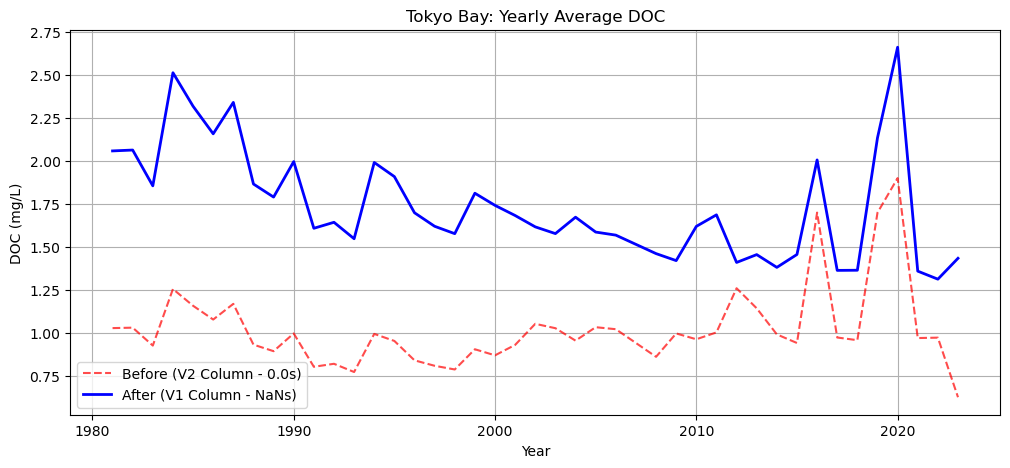

In [2]:
plt.figure(figsize=(12, 5))

# Filter to Tokyo Bay roughly
tokyo_mask = raw['watermass_name'] == 'Tokyo Bay'

# Aggregate by year
before_yearly = before_doc[tokyo_mask].groupby(years[tokyo_mask]).mean()
after_yearly = after_doc[tokyo_mask].groupby(years[tokyo_mask]).mean()

plt.plot(before_yearly.index, before_yearly.values, 'r--', label='Before (V2 Column - 0.0s)', alpha=0.7)
plt.plot(after_yearly.index, after_yearly.values, 'b-', label='After (V1 Column - NaNs)', linewidth=2)

plt.title('Tokyo Bay: Yearly Average DOC')
plt.xlabel('Year')
plt.ylabel('DOC (mg/L)')
plt.legend()
plt.grid(True)
plt.show()


## 2. Statistical Fix: Correlation Analysis
Let's simulate a Pearson Correlation test. The `pearsonr` function compares two arrays. 
If an array has `0.0`s instead of `NaN`s, `dropna()` will fail to filter them, causing massive false correlations.


In [3]:
# Create a fake "PC Score" time series for the sake of correlation testing
np.random.seed(42)
fake_pc = pd.Series(np.random.randn(len(before_yearly)), index=before_yearly.index)

# BEFORE: 0.0 values bypass dropna()
common_before = fake_pc.index.intersection(before_yearly.dropna().index)
corr_before, p_before = pearsonr(fake_pc.loc[common_before], before_yearly.loc[common_before])
print(f"BEFORE Correlation: r = {corr_before:.3f} (Calculated over {len(common_before)} years, including fake 0.0s)")

# AFTER: NaNs are successfully caught by dropna()
common_after = fake_pc.index.intersection(after_yearly.dropna().index)
corr_after, p_after = pearsonr(fake_pc.loc[common_after], after_yearly.loc[common_after])
print(f"AFTER Correlation: r = {corr_after:.3f} (Calculated strictly over {len(common_after)} true recorded years)")


BEFORE Correlation: r = -0.035 (Calculated over 42 years, including fake 0.0s)
AFTER Correlation: r = 0.014 (Calculated strictly over 42 true recorded years)
